# ALL CONDITIONS

Loaded:
F:\# study 2\eeg_data\erpac\PCA\erpac_roi_tc\LMM\pca_erpac_LMM_all_tasks.csv

Shape:
(4512, 14)

Columns:
['sub', 'group', 'task', 'task_stage', 'task_block', 'adaptation_split', 'condition', 'coupling', 'roi', 'mean_erpac', 'n_epochs', 'pca_variance_threshold', 'pca_n_components_retained', 'pca_actual_variance_retained']

Summary:
  group task_stage        condition     coupling      mean        sd   n  \
0     Y       plan              FTT  theta_gamma  0.149919  0.009505  23   
1     Y       plan              FTT  alpha_gamma  0.150971  0.010692  23   
2     Y       plan              FTT   beta_gamma  0.152728  0.009760  23   
3     Y       plan  DeCRAT_baseline  theta_gamma  0.185473  0.008680  23   
4     Y       plan  DeCRAT_baseline  alpha_gamma  0.186688  0.009440  23   

        sem  
0  0.001982  
1  0.002229  
2  0.002035  
3  0.001810  
4  0.001968  
Saved: F:\# study 2\eeg_data\erpac\PCA\erpac_roi_tc\LMM\plots\theta_gamma_group_stage_condition.png


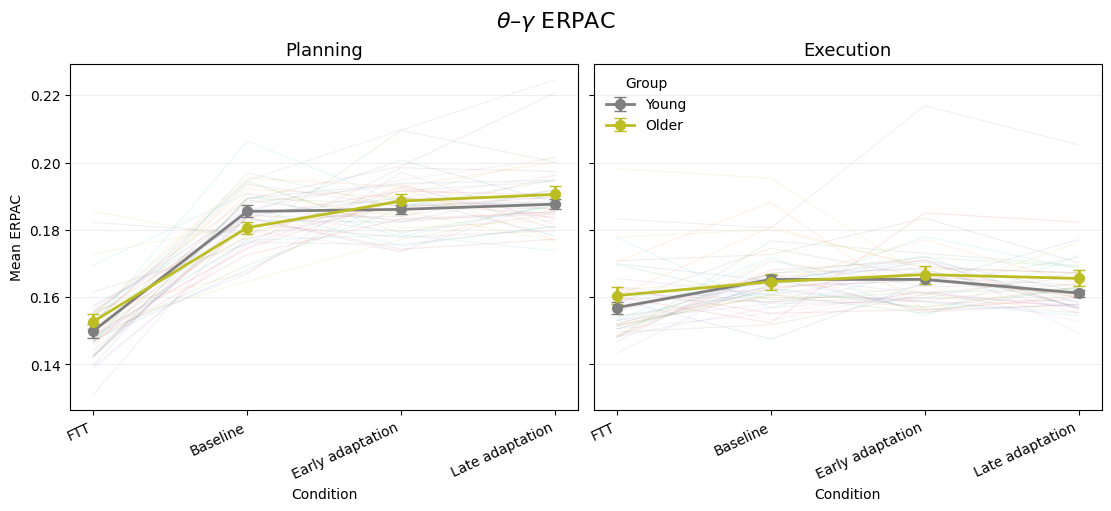

Saved: F:\# study 2\eeg_data\erpac\PCA\erpac_roi_tc\LMM\plots\alpha_gamma_group_stage_condition.png


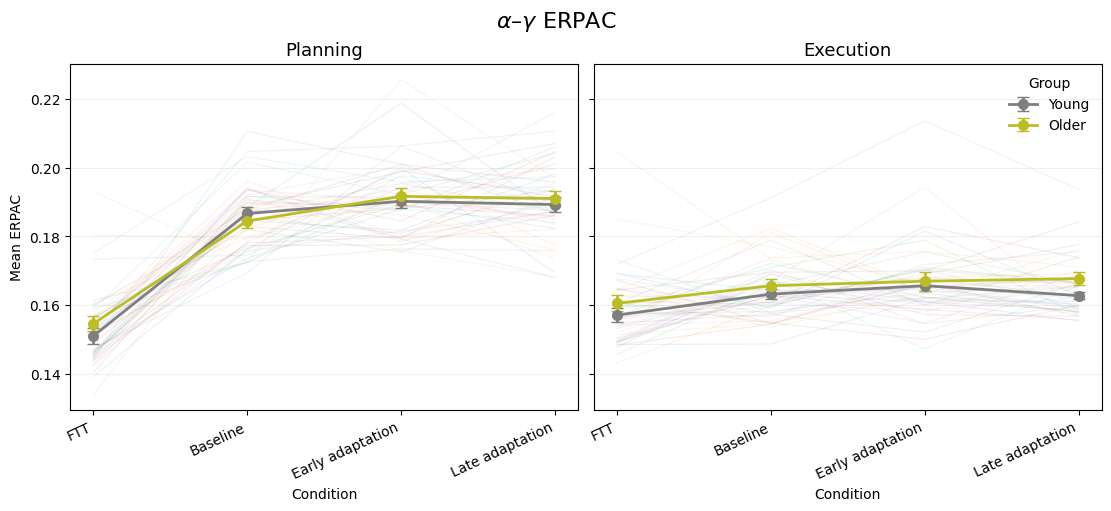

Saved: F:\# study 2\eeg_data\erpac\PCA\erpac_roi_tc\LMM\plots\beta_gamma_group_stage_condition.png


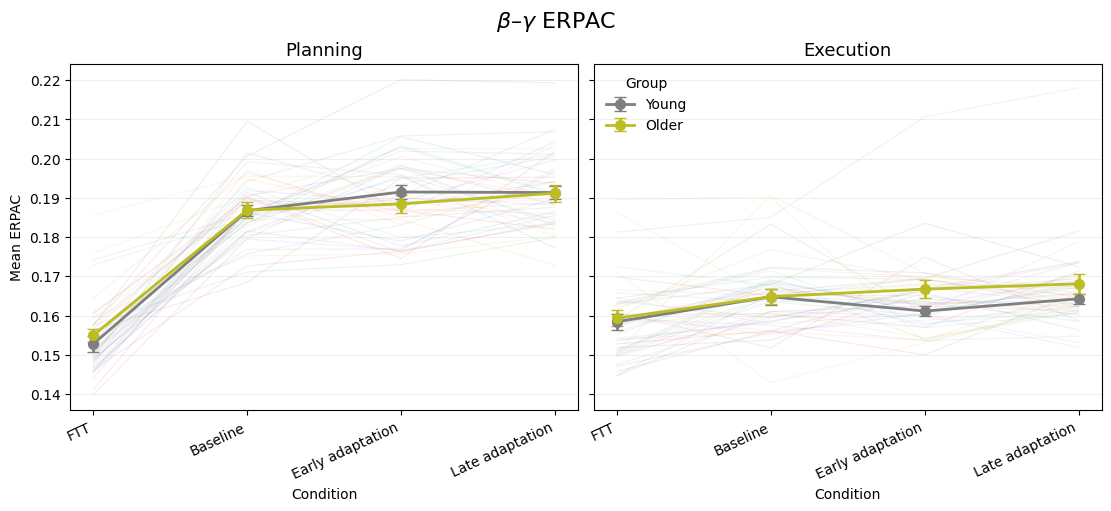

Saved: F:\# study 2\eeg_data\erpac\PCA\erpac_roi_tc\LMM\plots\theta_gamma_group_stage_condition_roi.png


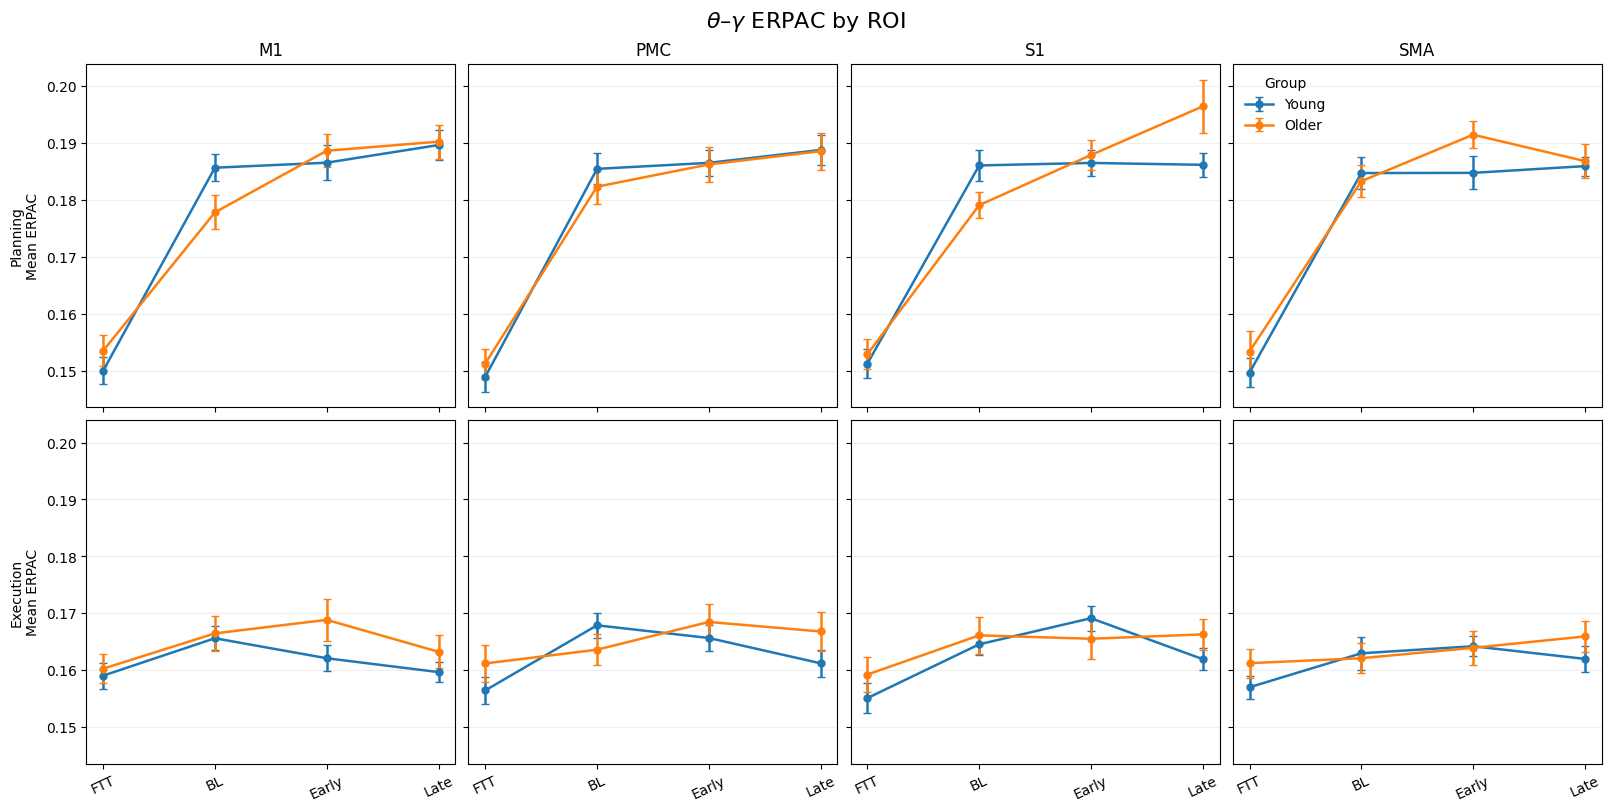

Saved: F:\# study 2\eeg_data\erpac\PCA\erpac_roi_tc\LMM\plots\alpha_gamma_group_stage_condition_roi.png


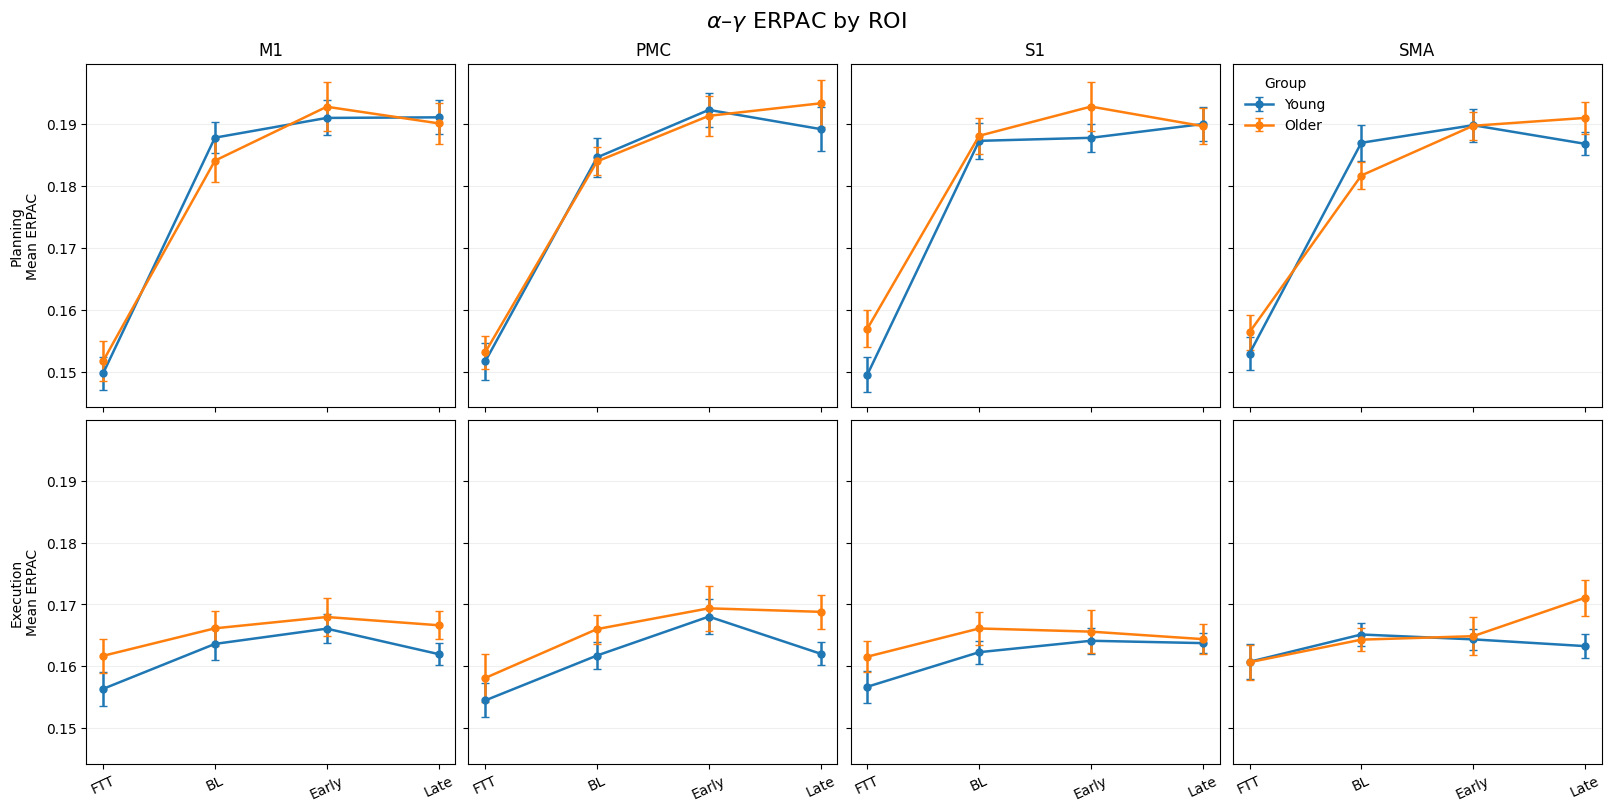

Saved: F:\# study 2\eeg_data\erpac\PCA\erpac_roi_tc\LMM\plots\beta_gamma_group_stage_condition_roi.png


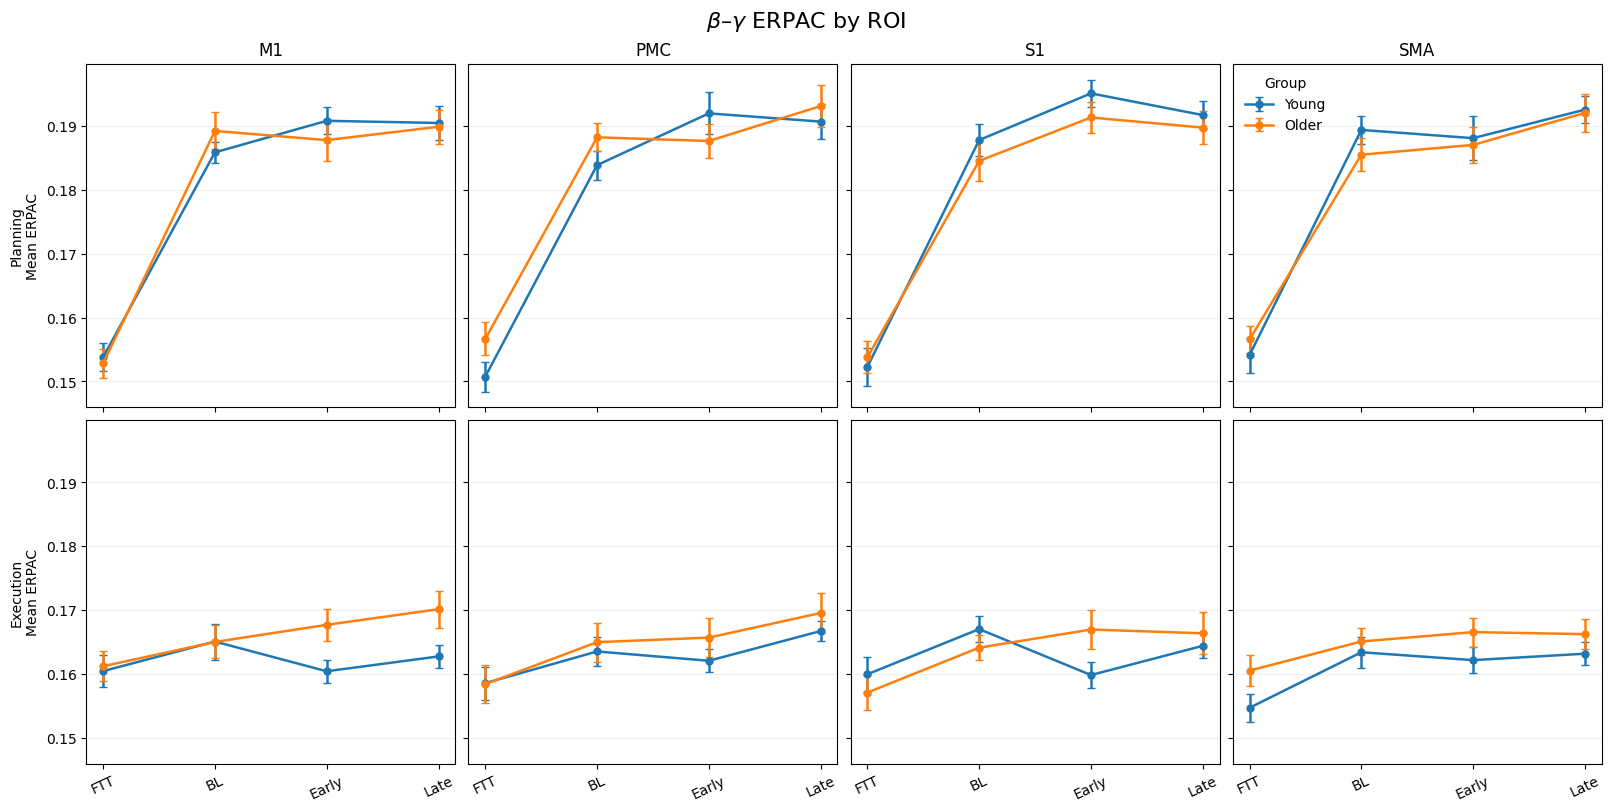


Saved summary: F:\# study 2\eeg_data\erpac\PCA\erpac_roi_tc\LMM\plots\ERPAC_group_stage_condition_summary.csv

Finished.


In [1]:
# ============================================================
# PLOT LMM ERPAC RESULTS
# ============================================================
#
# Primary visualization:
#
#   x-axis: condition
#   y-axis: mean ERPAC
#   lines: Young vs Older
#   panels: planning vs execution
#   separate figure for each coupling
#
# The primary figure averages across ROI because the LMM
# did not show significant Group × ROI interactions.
#
# Input:
#   pca_erpac_LMM_all_tasks.csv
#
# Expected columns:
#   sub
#   group
#   task_stage
#   condition
#   roi
#   coupling
#   mean_erpac
#
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# PATHS
# ============================================================

DATA_DIR = Path(
    r"F:\# study 2\eeg_data\erpac\PCA\erpac_roi_tc\LMM"
)

INPUT_FILE = DATA_DIR / "pca_erpac_LMM_all_tasks.csv"

OUTPUT_DIR = DATA_DIR / "plots"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# SETTINGS
# ============================================================

CONDITION_ORDER = [
    "FTT",
    "DeCRAT_baseline",
    "DeCRAT_adaptation_early",
    "DeCRAT_adaptation_late",
]

CONDITION_LABELS = {
    "FTT": "FTT",
    "DeCRAT_baseline": "Baseline",
    "DeCRAT_adaptation_early": "Early adaptation",
    "DeCRAT_adaptation_late": "Late adaptation",
}

STAGE_ORDER = [
    "plan",
    "go",
]

STAGE_LABELS = {
    "plan": "Planning",
    "go": "Execution",
}

GROUP_ORDER = [
    "Y",
    "O",
]

GROUP_LABELS = {
    "Y": "Young",
    "O": "Older",
}

COUPLING_ORDER = [
    "theta_gamma",
    "alpha_gamma",
    "beta_gamma",
]

COUPLING_LABELS = {
    "theta_gamma": r"$\theta$–$\gamma$",
    "alpha_gamma": r"$\alpha$–$\gamma$",
    "beta_gamma": r"$\beta$–$\gamma$",
}

ROI_ORDER = [
    "M1",
    "PMC",
    "S1",
    "SMA",
]


# ============================================================
# LOAD DATA
# ============================================================

df = pd.read_csv(INPUT_FILE)

print("Loaded:")
print(INPUT_FILE)

print("\nShape:")
print(df.shape)

print("\nColumns:")
print(df.columns.tolist())


# ============================================================
# CHECK REQUIRED COLUMNS
# ============================================================

required_columns = [
    "sub",
    "group",
    "task_stage",
    "condition",
    "roi",
    "coupling",
    "mean_erpac",
]

missing = [
    col for col in required_columns
    if col not in df.columns
]

if missing:
    raise ValueError(
        f"Missing required columns: {missing}"
    )


# Remove missing ERPAC values
df = df.dropna(subset=["mean_erpac"]).copy()


# ============================================================
# SET CATEGORY ORDER
# ============================================================

df["condition"] = pd.Categorical(
    df["condition"],
    categories=CONDITION_ORDER,
    ordered=True,
)

df["task_stage"] = pd.Categorical(
    df["task_stage"],
    categories=STAGE_ORDER,
    ordered=True,
)

df["group"] = pd.Categorical(
    df["group"],
    categories=GROUP_ORDER,
    ordered=True,
)

df["coupling"] = pd.Categorical(
    df["coupling"],
    categories=COUPLING_ORDER,
    ordered=True,
)

df["roi"] = pd.Categorical(
    df["roi"],
    categories=ROI_ORDER,
    ordered=True,
)


# ============================================================
# FIRST AVERAGE WITHIN SUBJECT ACROSS ROI
# ============================================================
#
# Important:
#
# We do NOT simply pool all ROI observations when calculating
# error bars.
#
# Instead:
#
# ROI values
#     ↓
# mean within each subject
#     ↓
# subject-level mean ERPAC
#     ↓
# group mean / SEM
#
# This ensures that the error bars reflect between-subject
# variability rather than treating ROIs as independent.
#
# ============================================================

subject_df = (
    df
    .groupby(
        [
            "sub",
            "group",
            "task_stage",
            "condition",
            "coupling",
        ],
        observed=True,
    )["mean_erpac"]
    .mean()
    .reset_index()
)


# ============================================================
# GROUP SUMMARY
# ============================================================

summary_df = (
    subject_df
    .groupby(
        [
            "group",
            "task_stage",
            "condition",
            "coupling",
        ],
        observed=True,
    )["mean_erpac"]
    .agg(
        mean="mean",
        sd="std",
        n="count",
    )
    .reset_index()
)

summary_df["sem"] = (
    summary_df["sd"] /
    np.sqrt(summary_df["n"])
)


print("\nSummary:")
print(summary_df.head())


# ============================================================
# HELPER FUNCTION
# ============================================================

def get_x_positions():
    """
    Return numerical x positions corresponding to conditions.
    """
    return np.arange(len(CONDITION_ORDER))


# ============================================================
# PRIMARY FIGURE
# GROUP × CONDITION
# SEPARATE PANELS FOR PLANNING / EXECUTION
# ============================================================

def plot_coupling_interaction(
    coupling,
    subject_df,
    summary_df,
    save_dir,
    show_subjects=True,
    dpi=300,
):

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(11, 5),
        sharey=True,
        constrained_layout=True,
    )

    x = get_x_positions()

    coupling_title = COUPLING_LABELS.get(
        coupling,
        coupling,
    )

    for ax, stage in zip(
        axes,
        STAGE_ORDER,
    ):

        # --------------------------------------------
        # SUBJECT-LEVEL DATA
        # --------------------------------------------

        if show_subjects:

            stage_subjects = subject_df[
                (subject_df["coupling"] == coupling)
                &
                (subject_df["task_stage"] == stage)
            ]

            for group in GROUP_ORDER:

                group_subjects = stage_subjects[
                    stage_subjects["group"] == group
                ]

                pivot = group_subjects.pivot(
                    index="sub",
                    columns="condition",
                    values="mean_erpac",
                )

                pivot = pivot.reindex(
                    columns=CONDITION_ORDER
                )

                for _, row in pivot.iterrows():

                    ax.plot(
                        x,
                        row.values,
                        alpha=0.10,
                        linewidth=0.8,
                    )


        # --------------------------------------------
        # GROUP MEAN ± SEM
        # --------------------------------------------

        for group in GROUP_ORDER:

            tmp = summary_df[
                (summary_df["coupling"] == coupling)
                &
                (summary_df["task_stage"] == stage)
                &
                (summary_df["group"] == group)
            ].copy()

            tmp = (
                tmp
                .set_index("condition")
                .reindex(CONDITION_ORDER)
                .reset_index()
            )

            ax.errorbar(
                x,
                tmp["mean"],
                yerr=tmp["sem"],
                marker="o",
                markersize=7,
                linewidth=2,
                capsize=4,
                label=GROUP_LABELS[group],
            )


        # --------------------------------------------
        # PANEL FORMATTING
        # --------------------------------------------

        ax.set_title(
            STAGE_LABELS[stage],
            fontsize=13,
        )

        ax.set_xticks(x)

        ax.set_xticklabels(
            [
                CONDITION_LABELS[c]
                for c in CONDITION_ORDER
            ],
            rotation=25,
            ha="right",
        )

        ax.set_xlabel("Condition")

        ax.grid(
            axis="y",
            alpha=0.2,
        )


    axes[0].set_ylabel("Mean ERPAC")

    axes[1].legend(
        title="Group",
        frameon=False,
    )

    fig.suptitle(
        f"{coupling_title} ERPAC",
        fontsize=16,
    )


    # --------------------------------------------
    # SAVE
    # --------------------------------------------

    output_file = (
        save_dir /
        f"{coupling}_group_stage_condition.png"
    )

    fig.savefig(
        output_file,
        dpi=dpi,
        bbox_inches="tight",
    )

    print(
        f"Saved: {output_file}"
    )

    return fig


# ============================================================
# CREATE PRIMARY FIGURES
# ============================================================

for coupling in COUPLING_ORDER:

    fig = plot_coupling_interaction(
        coupling=coupling,
        subject_df=subject_df,
        summary_df=summary_df,
        save_dir=OUTPUT_DIR,
    )

    plt.show()
    plt.close(fig)


# ============================================================
# SECONDARY FIGURE
# ROI-SPECIFIC PLOTS
# ============================================================
#
# These are useful as supplementary figures.
#
# Rows:
#   planning
#   execution
#
# Columns:
#   M1
#   PMC
#   S1
#   SMA
#
# ============================================================

def plot_roi_interaction(
    coupling,
    df,
    save_dir,
    dpi=300,
):

    fig, axes = plt.subplots(
        2,
        4,
        figsize=(16, 8),
        sharex=True,
        sharey=True,
        constrained_layout=True,
    )

    x = get_x_positions()

    coupling_title = COUPLING_LABELS.get(
        coupling,
        coupling,
    )

    for row_idx, stage in enumerate(STAGE_ORDER):

        for col_idx, roi in enumerate(ROI_ORDER):

            ax = axes[
                row_idx,
                col_idx,
            ]

            roi_df = df[
                (df["coupling"] == coupling)
                &
                (df["task_stage"] == stage)
                &
                (df["roi"] == roi)
            ].copy()


            # ----------------------------------------
            # GROUP SUMMARY
            # ----------------------------------------

            roi_summary = (
                roi_df
                .groupby(
                    [
                        "group",
                        "condition",
                    ],
                    observed=True,
                )["mean_erpac"]
                .agg(
                    mean="mean",
                    sd="std",
                    n="count",
                )
                .reset_index()
            )

            roi_summary["sem"] = (
                roi_summary["sd"] /
                np.sqrt(
                    roi_summary["n"]
                )
            )


            # ----------------------------------------
            # PLOT GROUPS
            # ----------------------------------------

            for group in GROUP_ORDER:

                tmp = roi_summary[
                    roi_summary["group"] == group
                ].copy()

                tmp = (
                    tmp
                    .set_index("condition")
                    .reindex(CONDITION_ORDER)
                    .reset_index()
                )

                ax.errorbar(
                    x,
                    tmp["mean"],
                    yerr=tmp["sem"],
                    marker="o",
                    markersize=5,
                    linewidth=1.8,
                    capsize=3,
                    label=GROUP_LABELS[group],
                )


            # ----------------------------------------
            # TITLES
            # ----------------------------------------

            if row_idx == 0:
                ax.set_title(
                    roi,
                    fontsize=12,
                )

            if col_idx == 0:
                ax.set_ylabel(
                    f"{STAGE_LABELS[stage]}\nMean ERPAC"
                )


            ax.set_xticks(x)

            ax.set_xticklabels(
                [
                    "FTT",
                    "BL",
                    "Early",
                    "Late",
                ],
                rotation=25,
            )

            ax.grid(
                axis="y",
                alpha=0.2,
            )


    axes[0, -1].legend(
        title="Group",
        frameon=False,
    )

    fig.suptitle(
        f"{coupling_title} ERPAC by ROI",
        fontsize=16,
    )


    output_file = (
        save_dir /
        f"{coupling}_group_stage_condition_roi.png"
    )

    fig.savefig(
        output_file,
        dpi=dpi,
        bbox_inches="tight",
    )

    print(
        f"Saved: {output_file}"
    )

    return fig


# ============================================================
# CREATE ROI FIGURES
# ============================================================

for coupling in COUPLING_ORDER:

    fig = plot_roi_interaction(
        coupling=coupling,
        df=df,
        save_dir=OUTPUT_DIR,
    )

    plt.show()
    plt.close(fig)


# ============================================================
# SAVE SUMMARY DATA
# ============================================================

summary_file = (
    OUTPUT_DIR /
    "ERPAC_group_stage_condition_summary.csv"
)

summary_df.to_csv(
    summary_file,
    index=False,
)

print(
    f"\nSaved summary: {summary_file}"
)

print("\nFinished.")

# TARGETED

Raw data: (4512, 14)
Targeted group contrasts: (12, 10)
Stage × Condition EMMs: (24, 8)
Stage contrasts: (12, 8)
Saved: F:\# study 2\eeg_data\erpac\PCA\erpac_roi_tc\LMM\plots_revised\theta_gamma_group_stage_condition.png


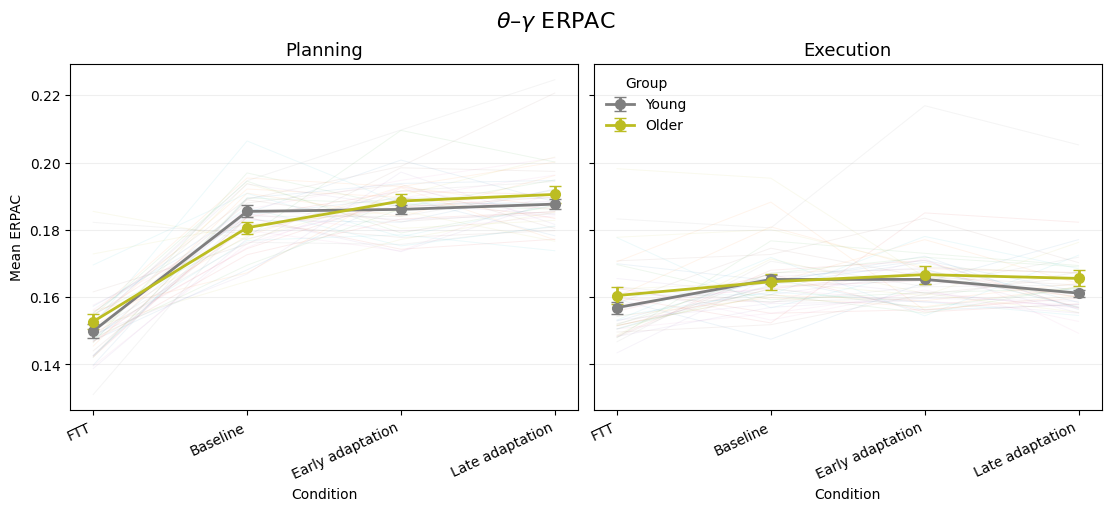

Saved: F:\# study 2\eeg_data\erpac\PCA\erpac_roi_tc\LMM\plots_revised\alpha_gamma_group_stage_condition.png


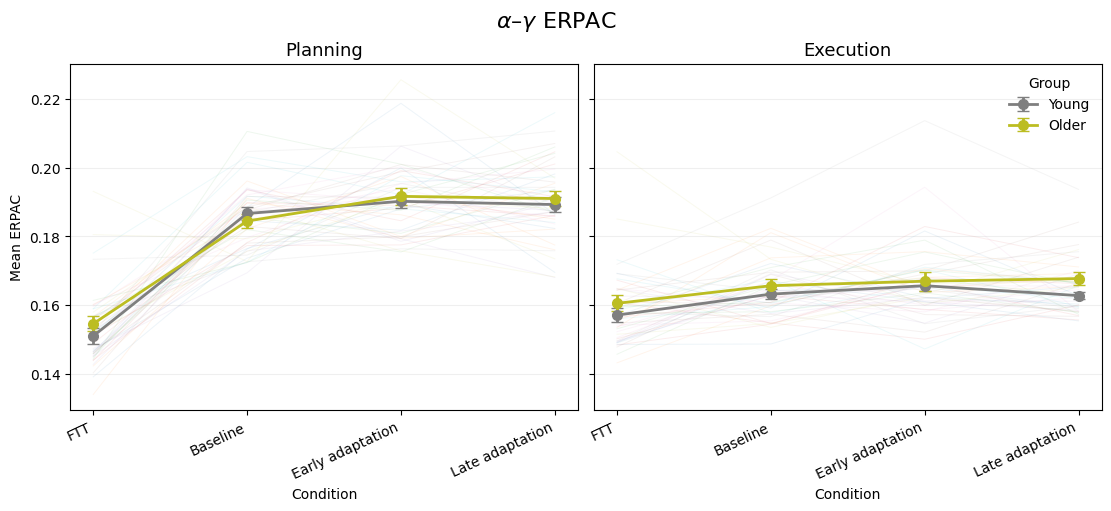

Saved: F:\# study 2\eeg_data\erpac\PCA\erpac_roi_tc\LMM\plots_revised\beta_gamma_group_stage_condition.png


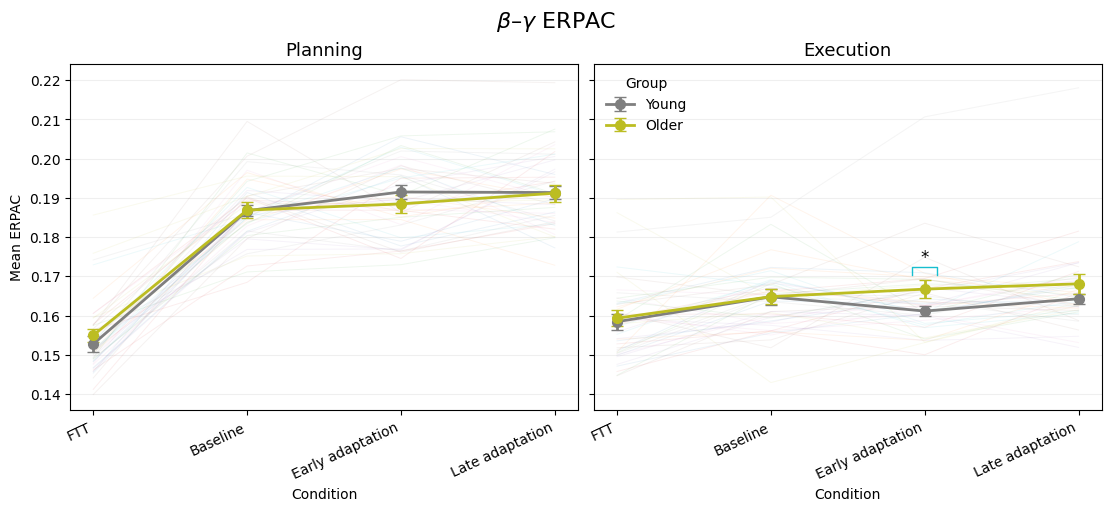

Saved: F:\# study 2\eeg_data\erpac\PCA\erpac_roi_tc\LMM\plots_revised\theta_gamma_group_condition_collapsed.png


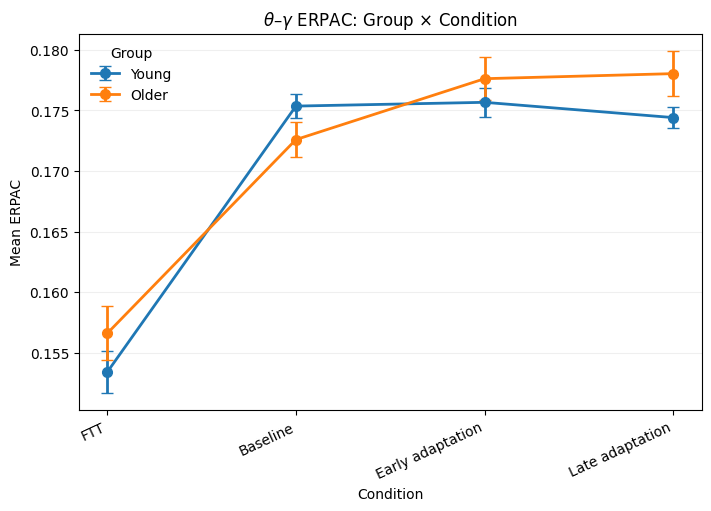

Saved: F:\# study 2\eeg_data\erpac\PCA\erpac_roi_tc\LMM\plots_revised\theta_gamma_stage_condition_emmeans.png


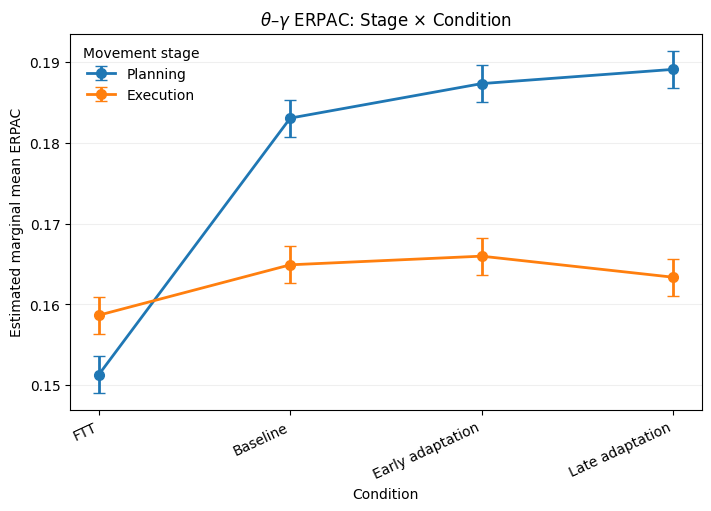

Saved: F:\# study 2\eeg_data\erpac\PCA\erpac_roi_tc\LMM\plots_revised\alpha_gamma_stage_condition_emmeans.png


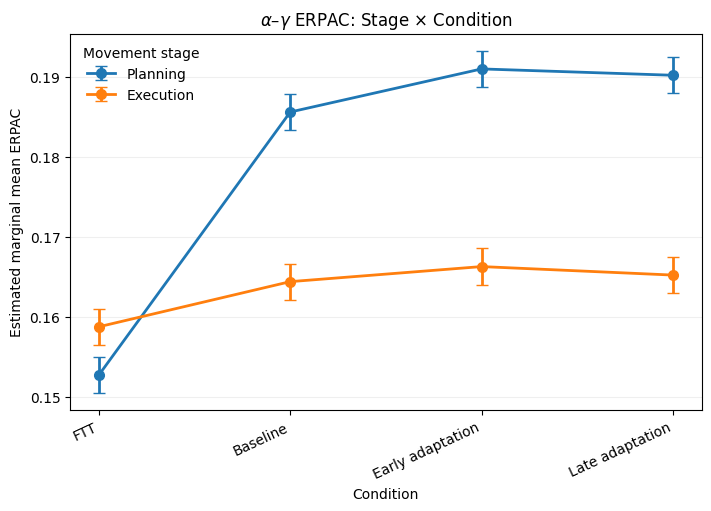

Saved: F:\# study 2\eeg_data\erpac\PCA\erpac_roi_tc\LMM\plots_revised\beta_gamma_stage_condition_emmeans.png


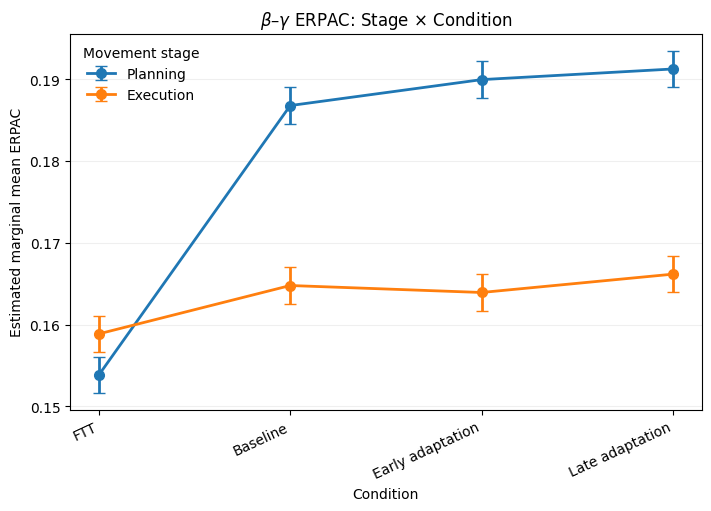


Finished.
Plots saved to: F:\# study 2\eeg_data\erpac\PCA\erpac_roi_tc\LMM\plots_revised


In [2]:
# ============================================================
# PLOT UPDATED ERPAC LMM RESULTS
#
# Matches revised R analysis:
#
# theta-gamma:
#   Group × Condition significant
#   -> Young vs Old within condition
#      averaged across stage and ROI
#
# alpha-gamma:
#   no significant Group-related interaction
#   -> no confirmatory Young vs Old annotations
#
# beta-gamma:
#   Group × Stage × Condition significant
#   -> Young vs Old within Stage × Condition
#      averaged across ROI
#
# Also plots Stage × Condition EMMs from R.
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# PATHS
# ============================================================

DATA_DIR = Path(r"F:\# study 2\eeg_data\erpac\PCA\erpac_roi_tc\LMM")
INPUT_FILE = DATA_DIR / "pca_erpac_LMM_all_tasks.csv"

GROUP_CONTRAST_FILE = DATA_DIR / "ERPAC_LMM_targeted_group_contrasts.csv"
STAGE_EMM_FILE = DATA_DIR / "ERPAC_LMM_stage_condition_emmeans.csv"
STAGE_CONTRAST_FILE = DATA_DIR / "ERPAC_LMM_stage_contrasts.csv"

OUTPUT_DIR = DATA_DIR / "plots_revised"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ============================================================
# SETTINGS
# ============================================================

CONDITION_ORDER = [
    "FTT",
    "DeCRAT_baseline",
    "DeCRAT_adaptation_early",
    "DeCRAT_adaptation_late",
]

CONDITION_LABELS = {
    "FTT": "FTT",
    "DeCRAT_baseline": "Baseline",
    "DeCRAT_adaptation_early": "Early adaptation",
    "DeCRAT_adaptation_late": "Late adaptation",
}

STAGE_ORDER = ["plan", "go"]

STAGE_LABELS = {
    "plan": "Planning",
    "go": "Execution",
}

GROUP_ORDER = ["Y", "O"]

GROUP_LABELS = {
    "Y": "Young",
    "O": "Older",
}

COUPLING_ORDER = [
    "theta_gamma",
    "alpha_gamma",
    "beta_gamma",
]

COUPLING_LABELS = {
    "theta_gamma": r"$\theta$–$\gamma$",
    "alpha_gamma": r"$\alpha$–$\gamma$",
    "beta_gamma": r"$\beta$–$\gamma$",
}

# ============================================================
# LOAD DATA
# ============================================================

df = pd.read_csv(INPUT_FILE)
group_contrasts = pd.read_csv(GROUP_CONTRAST_FILE)
stage_emm = pd.read_csv(STAGE_EMM_FILE)
stage_contrasts = pd.read_csv(STAGE_CONTRAST_FILE)

df = df.dropna(subset=["mean_erpac"]).copy()

print("Raw data:", df.shape)
print("Targeted group contrasts:", group_contrasts.shape)
print("Stage × Condition EMMs:", stage_emm.shape)
print("Stage contrasts:", stage_contrasts.shape)

# ============================================================
# CATEGORY ORDER
# ============================================================

df["condition"] = pd.Categorical(
    df["condition"], categories=CONDITION_ORDER, ordered=True
)

df["task_stage"] = pd.Categorical(
    df["task_stage"], categories=STAGE_ORDER, ordered=True
)

df["group"] = pd.Categorical(
    df["group"], categories=GROUP_ORDER, ordered=True
)

# ============================================================
# HELPER FUNCTIONS
# ============================================================

def p_to_stars(p):
    """Convert p-value to significance label."""
    if pd.isna(p):
        return ""
    if p < 0.001:
        return "***"
    if p < 0.01:
        return "**"
    if p < 0.05:
        return "*"
    return ""


def subject_average_across_roi(data):
    """
    Average ROI values within each subject.

    Result:
    one value per subject × group × stage × condition × coupling.
    """
    return (
        data.groupby(
            ["sub", "group", "task_stage", "condition", "coupling"],
            observed=True,
        )["mean_erpac"]
        .mean()
        .reset_index()
    )


def group_summary(data):
    """Calculate mean and SEM across subjects."""
    out = (
        data.groupby(
            ["group", "task_stage", "condition", "coupling"],
            observed=True,
        )["mean_erpac"]
        .agg(mean="mean", sd="std", n="count")
        .reset_index()
    )

    out["sem"] = out["sd"] / np.sqrt(out["n"])
    return out


subject_df = subject_average_across_roi(df)
summary_df = group_summary(subject_df)

# ============================================================
# SIGNIFICANCE ANNOTATION
# ============================================================

def add_significance(ax, x, y1, y2, p, height_fraction=0.04):
    """Add Young vs Old significance bracket."""
    stars = p_to_stars(p)

    if not stars:
        return

    ymin, ymax = ax.get_ylim()
    yrange = ymax - ymin

    y = max(y1, y2) + yrange * height_fraction
    h = yrange * 0.025

    ax.plot(
        [x - 0.08, x - 0.08, x + 0.08, x + 0.08],
        [y, y + h, y + h, y],
        linewidth=1,
    )

    ax.text(
        x,
        y + h,
        stars,
        ha="center",
        va="bottom",
        fontsize=12,
    )


# ============================================================
# PRIMARY FIGURE
# GROUP × STAGE × CONDITION
# ============================================================

def plot_age_interaction(coupling, show_subjects=True, dpi=300):

    coupling_subjects = subject_df[
        subject_df["coupling"] == coupling
    ].copy()

    coupling_summary = summary_df[
        summary_df["coupling"] == coupling
    ].copy()

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(11, 5),
        sharey=True,
        constrained_layout=True,
    )

    x = np.arange(len(CONDITION_ORDER))

    for ax, stage in zip(axes, STAGE_ORDER):

        stage_subjects = coupling_subjects[
            coupling_subjects["task_stage"] == stage
        ]

        stage_summary = coupling_summary[
            coupling_summary["task_stage"] == stage
        ]

        # --------------------------------------------
        # Subject trajectories
        # --------------------------------------------

        if show_subjects:
            for group in GROUP_ORDER:

                tmp = stage_subjects[
                    stage_subjects["group"] == group
                ]

                pivot = tmp.pivot(
                    index="sub",
                    columns="condition",
                    values="mean_erpac",
                ).reindex(columns=CONDITION_ORDER)

                for _, row in pivot.iterrows():
                    ax.plot(
                        x,
                        row.values,
                        linewidth=0.7,
                        alpha=0.08,
                    )

        # --------------------------------------------
        # Group means ± SEM
        # --------------------------------------------

        plotted_values = {}

        for group in GROUP_ORDER:

            tmp = (
                stage_summary[
                    stage_summary["group"] == group
                ]
                .set_index("condition")
                .reindex(CONDITION_ORDER)
            )

            means = tmp["mean"].to_numpy()
            sems = tmp["sem"].to_numpy()

            plotted_values[group] = means

            ax.errorbar(
                x,
                means,
                yerr=sems,
                marker="o",
                markersize=7,
                linewidth=2,
                capsize=4,
                label=GROUP_LABELS[group],
            )

        ax.set_title(STAGE_LABELS[stage], fontsize=13)
        ax.set_xticks(x)
        ax.set_xticklabels(
            [CONDITION_LABELS[c] for c in CONDITION_ORDER],
            rotation=25,
            ha="right",
        )
        ax.set_xlabel("Condition")
        ax.grid(axis="y", alpha=0.2)

        # --------------------------------------------
        # Beta-gamma:
        # Young vs Old within Stage × Condition
        # --------------------------------------------

        if coupling == "beta_gamma":

            contrast_tmp = group_contrasts[
                (group_contrasts["coupling"] == coupling)
                & (group_contrasts["task_stage"] == stage)
            ]

            for i, condition in enumerate(CONDITION_ORDER):

                row = contrast_tmp[
                    contrast_tmp["condition"] == condition
                ]

                if row.empty:
                    continue

                p = row.iloc[0]["p.value"]

                add_significance(
                    ax=ax,
                    x=i,
                    y1=plotted_values["Y"][i],
                    y2=plotted_values["O"][i],
                    p=p,
                )

    axes[0].set_ylabel("Mean ERPAC")
    axes[1].legend(title="Group", frameon=False)

    fig.suptitle(
        f"{COUPLING_LABELS[coupling]} ERPAC",
        fontsize=16,
    )

    output = OUTPUT_DIR / f"{coupling}_group_stage_condition.png"

    fig.savefig(
        output,
        dpi=dpi,
        bbox_inches="tight",
    )

    print("Saved:", output)

    return fig


# ============================================================
# THETA-GAMMA COLLAPSED CONDITION PLOT
#
# Matches the significant Group × Condition interaction.
# Averaged across ROI AND movement stage.
# ============================================================

def plot_theta_group_condition(dpi=300):

    tmp = df[
        df["coupling"] == "theta_gamma"
    ].copy()

    # Average across ROI + stage within subject
    subject_condition = (
        tmp.groupby(
            ["sub", "group", "condition"],
            observed=True,
        )["mean_erpac"]
        .mean()
        .reset_index()
    )

    summary = (
        subject_condition.groupby(
            ["group", "condition"],
            observed=True,
        )["mean_erpac"]
        .agg(mean="mean", sd="std", n="count")
        .reset_index()
    )

    summary["sem"] = summary["sd"] / np.sqrt(summary["n"])

    fig, ax = plt.subplots(
        figsize=(7, 5),
        constrained_layout=True,
    )

    x = np.arange(len(CONDITION_ORDER))
    plotted_values = {}

    for group in GROUP_ORDER:

        g = (
            summary[
                summary["group"] == group
            ]
            .set_index("condition")
            .reindex(CONDITION_ORDER)
        )

        means = g["mean"].to_numpy()
        sems = g["sem"].to_numpy()

        plotted_values[group] = means

        ax.errorbar(
            x,
            means,
            yerr=sems,
            marker="o",
            markersize=7,
            linewidth=2,
            capsize=4,
            label=GROUP_LABELS[group],
        )

    ax.set_xticks(x)
    ax.set_xticklabels(
        [CONDITION_LABELS[c] for c in CONDITION_ORDER],
        rotation=25,
        ha="right",
    )

    ax.set_ylabel("Mean ERPAC")
    ax.set_xlabel("Condition")
    ax.set_title(
        r"$\theta$–$\gamma$ ERPAC: Group × Condition"
    )

    ax.grid(axis="y", alpha=0.2)
    ax.legend(title="Group", frameon=False)

    # Targeted theta-gamma contrasts
    contrasts = group_contrasts[
        group_contrasts["coupling"] == "theta_gamma"
    ]

    for i, condition in enumerate(CONDITION_ORDER):

        row = contrasts[
            contrasts["condition"] == condition
        ]

        if row.empty:
            continue

        p = row.iloc[0]["p.value"]

        add_significance(
            ax=ax,
            x=i,
            y1=plotted_values["Y"][i],
            y2=plotted_values["O"][i],
            p=p,
        )

    output = OUTPUT_DIR / "theta_gamma_group_condition_collapsed.png"

    fig.savefig(
        output,
        dpi=dpi,
        bbox_inches="tight",
    )

    print("Saved:", output)

    return fig


# ============================================================
# STAGE × CONDITION EMM FIGURE
#
# Uses EMMs generated directly in R.
#
# These are averaged across Group and ROI.
# ============================================================

def plot_stage_condition_emm(coupling, dpi=300):

    tmp = stage_emm[
        stage_emm["coupling"] == coupling
    ].copy()

    fig, ax = plt.subplots(
        figsize=(7, 5),
        constrained_layout=True,
    )

    x = np.arange(len(CONDITION_ORDER))

    for stage in STAGE_ORDER:

        stage_df = (
            tmp[
                tmp["task_stage"] == stage
            ]
            .set_index("condition")
            .reindex(CONDITION_ORDER)
        )

        means = stage_df["emmean"].to_numpy()

        # Prefer confidence intervals generated by emmeans
        if (
            "lower_ci" in stage_df.columns
            and "upper_ci" in stage_df.columns
        ):

            lower = means - stage_df["lower_ci"].to_numpy()
            upper = stage_df["upper_ci"].to_numpy() - means

            yerr = np.vstack([lower, upper])

        elif "SE" in stage_df.columns:
            yerr = stage_df["SE"].to_numpy()

        else:
            yerr = None

        ax.errorbar(
            x,
            means,
            yerr=yerr,
            marker="o",
            markersize=7,
            linewidth=2,
            capsize=4,
            label=STAGE_LABELS[stage],
        )

    ax.set_xticks(x)
    ax.set_xticklabels(
        [CONDITION_LABELS[c] for c in CONDITION_ORDER],
        rotation=25,
        ha="right",
    )

    ax.set_xlabel("Condition")
    ax.set_ylabel("Estimated marginal mean ERPAC")
    ax.set_title(
        f"{COUPLING_LABELS[coupling]} ERPAC: Stage × Condition"
    )

    ax.legend(title="Movement stage", frameon=False)
    ax.grid(axis="y", alpha=0.2)

    output = OUTPUT_DIR / f"{coupling}_stage_condition_emmeans.png"

    fig.savefig(
        output,
        dpi=dpi,
        bbox_inches="tight",
    )

    print("Saved:", output)

    return fig


# ============================================================
# CREATE FIGURES
# ============================================================

# 1. Main age-group figures
for coupling in COUPLING_ORDER:

    fig = plot_age_interaction(
        coupling=coupling,
        show_subjects=True,
    )

    plt.show()
    plt.close(fig)


# 2. Theta-gamma figure matching Group × Condition
fig = plot_theta_group_condition()
plt.show()
plt.close(fig)


# 3. Stage × Condition figures from R EMMs
for coupling in COUPLING_ORDER:

    fig = plot_stage_condition_emm(
        coupling=coupling
    )

    plt.show()
    plt.close(fig)


print("\nFinished.")
print("Plots saved to:", OUTPUT_DIR)